## **CA2 Part A:**
### **Name: Cayden Sim**
### **Student ID: P2510893**
### **Class: DAAA/FT/1B/01**

---

## **Background Overview:**
- Information of 200 customers were collected and they include:
    - Gender
    - Age
    - Income
    - How much they spend
- The purpose of this study is to apply unsupervised machine learning techniques to segment customers into meaningful groups. 
    - By identifying distinct customer clusters, organisations can better understand customer behaviour and tailor strategies to meet the needs of different customer segments more effectively.

## **Planned Workflow:**
-  ### Oveerall Workflow includes:
    - Data Exploration (EDA)
        - Understand data distribution, patterns and relationships
        - Identify potential outliers/anomalies
    - Preprocessing
        - Handle any missing values
        - Feature Engineering
    - Model Building and Implementation
        - Apply different clustering models to group customers.
    - Evaluation
        - Determine most optimal number of clusters for each model.
        - Analyse cluster quality with the appropriate metrics (Graphs, visuals, etc.).
    - Model Improvement
        - Compare results across multiple clustering model
        - Determine most suitable model that achieves the best result
        - Fine-tune selected model


- ### **Libraries Used:**
    - **Data Manipulation & Numerical Operation**
        - pandas
        - numpy
    - **Machine Learning:**
        - scikit-learn
    - **Data Visualization**
        - matplotlib
        - Seaborn


## **Ultimate End Goal:**
The ultimate goal of this project is to perform customer segmentation using unsupervised learning techniques. By clustering customers based on demographic and spending behaviour, the study aims to:

- Identify distinct customer groups

- Analyse the characteristics of each cluster

- Determine which customer segment requires the most attention from a business perspective

These insights can help organisations make more data-driven decisions in marketing, customer engagement, and resource allocation.

---

## **Step 1:** Importing Necessary Libraries and Modules

- Import the required libraries as well as modules for this assignment

In [1]:
# Importing libraries and modules
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler


- Libraries added include:
    - pandas
    - numpy
    - matplotlib
    - seaborn
- **pandas** and **numpy** are used for data handling and analysis.
- **matplotlib** and **seaborn** are used to display visuals and graphs.

--- 
## **Step 2:** Importing Dataset by Loading its CSV File

- Import downloaded dataset from the file explorer.

In [2]:
# Loading dataset's csv file with .read_csv()
customer_df = pd.read_csv("C:/Users/nedya/OneDrive/Desktop/AIML/CA2/CA2 Datasets/CA2-Customer-Data.csv")

- Customer Data dataset is imported via pandas' **`.read_csv()`** method.
- Dataset is stored into a variable **`'customer_df'`**.

--- 
## **Step 3:** Exploratory Data Analysis **(EDA)**

- ### **Planned Overview**: 
    - Showcase dataset's information.

    - Check for missing data in columns. 

    - Identifying major outliers that can affect the output of the machine.

    - Visualize data spread with graphs.

    - Identifying any relationships between columns via pairplot/correlation heatmap

    - **Numerical Columns**: Age, Income (k$), How Much They Spend

    - **Categorical Columns**: Gender, Customer ID

In [3]:
print("Here is a quick look at the DataFrame:")
customer_df

Here is a quick look at the DataFrame:


,CustomerID,Gender,Age,Income (k$),How Much They Spend
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


- Here is how the original DataFrame of customer data looks like.

In [4]:
print("Here is the shape of the DataFrame: ", customer_df.shape)
customer_df.info()

Here is the shape of the DataFrame:  (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   CustomerID           200 non-null    int64 
 1   Gender               200 non-null    object
 2   Age                  200 non-null    int64 
 3   Income (k$)          200 non-null    int64 
 4   How Much They Spend  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


- Using the **`.shape`** attribute and printing it shows that the customer dataset has **200 rows** and **5 columns**.
- Using the **`.info()`** method on the DataFrame prints its information.
    - From the output, it is shown that all rows are **`non-null`**, indicating that there are no empty data cells.
    - **`dtype`** shows the types of data in each column.

In [5]:
print("DataFrame Description:")
customer_df.describe()

DataFrame Description:


,CustomerID,Age,Income (k$),How Much They Spend
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


- The **`describe()`** summary provides an overview of key statistical properties such as the mean, standard deviation, and minimum/maximum values for each numerical feature. 

---
## **Step 3.5 - Continutinuation of EDA:** Plotting Visuals

- Some visuals will be plotted for better visualization and analysis of the original features.
- These visuals represents the relationship of each feature with another.

*Before adding new features and PCA

## **Visual Representation 1: Boxplot**

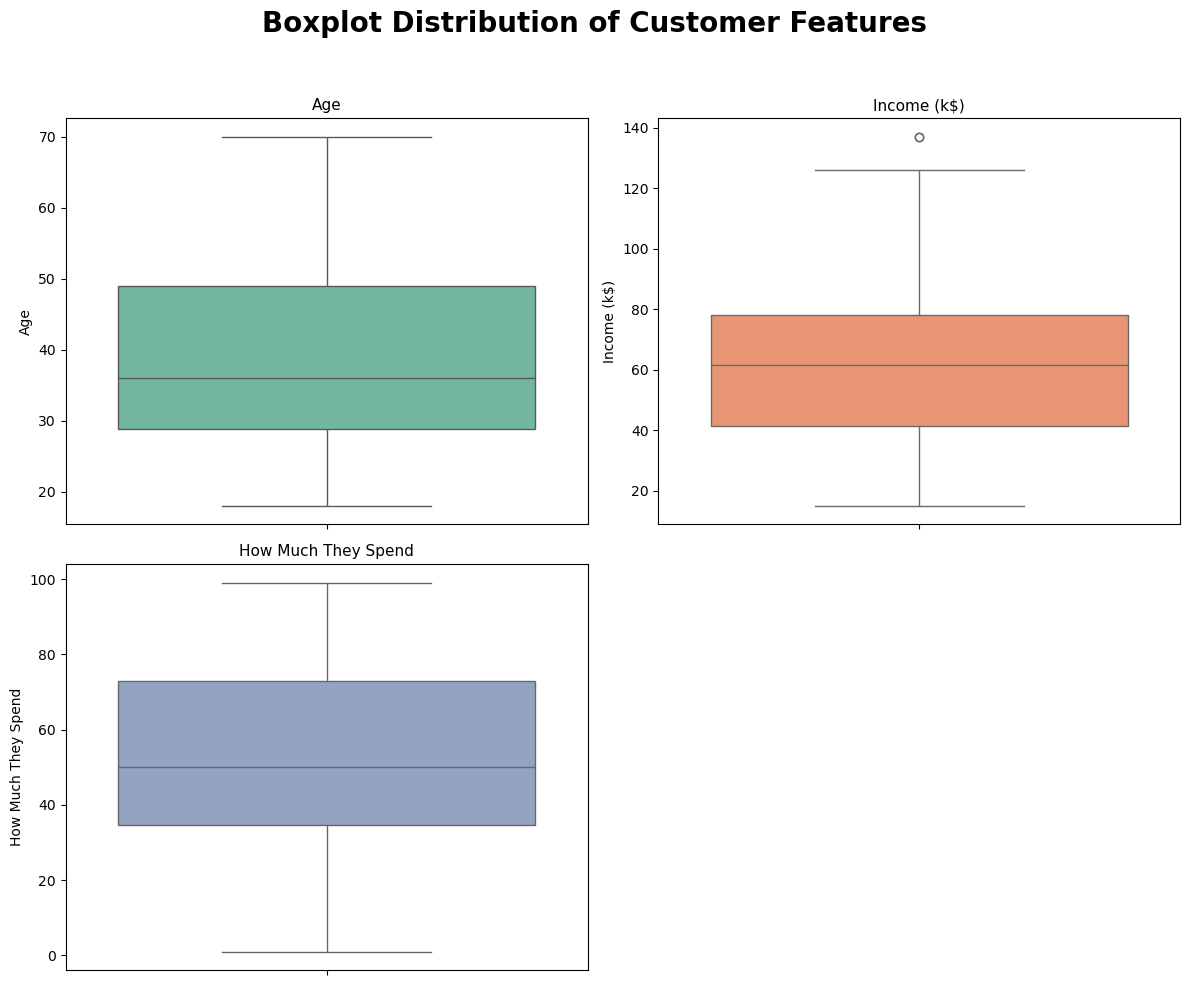

,mean,median,std
Age,38.85,36.0,13.97
Income (k$),60.56,61.5,26.26
How Much They Spend,50.20,50.0,25.82


In [6]:
# Make a list called featured_cols and store variables that will be featured in the boxplot
featured_cols = ['Age', 'Income (k$)', 'How Much They Spend']
palette = sns.color_palette("Set2", n_colors=3)

plt.figure(figsize=(12, 10))
plt.suptitle('Boxplot Distribution of Customer Features', fontsize=20, fontweight='bold') 
for i, feature in enumerate(featured_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(
        y=customer_df[feature],
        color=palette[i-1]
    )
    plt.title(feature, fontsize=11)

    # Y-axis shows the actual values of each feature
    plt.ylabel(feature)

# Adjust layout so title and plots don’t overlap
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Summary statistics for quick numeric insight
summary_stats = customer_df[featured_cols].agg(['mean', 'median', 'std']).T

# Rounded for cleaner presentation
display(summary_stats.round(2))


# # Features you want to compare
# feature_cols = ['Age', 'Income (k$)', 'How Much They Spend']

# # Mean table by Gender (expects Gender values like 'Male'/'Female')
# feature_means = customer_df.groupby('Gender')[feature_cols].mean().T

# # Ensure consistent column order if both exist
# feature_means = feature_means[['Female', 'Male']] if set(['Female','Male']).issubset(feature_means.columns) else feature_means

# # Difference: Male - Female (positive means higher for Male)
# if set(['Female','Male']).issubset(feature_means.columns):
#     feature_means['Difference'] = feature_means['Male'] - feature_means['Female']
# else:
#     # fallback if Gender is encoded as 0/1 or other labels
#     cols = list(feature_means.columns)
#     feature_means['Difference'] = feature_means[cols[1]] - feature_means[cols[0]]

# display(feature_means.sort_values('Difference', ascending=False).round(3))



- The boxplot is used to visualise the distribution of each numerical feature in the DataFrame that includes: Age, Income (k$), and How Much They Spend.

### **Key Insights of the Boxplot:**
- Age Distribution: 
    - Median customer age is around the mid-30s (35-36), suggesting that most customers fall within the young to middle-aged adult group.
    - Interquartile Range (IQR) is moderately wide, suggesting a diverse range and moderate spread of the ages rather than a single dominant age group.
    - There are no extreme outliers
- Income Distribution:
    - Income shows a wider spread than age in terms of the IQR, indicating a significant variation in customer earnings.
    - There is a single, high-income outlier that may suggest that a small group of customers earn more than the average income the majority of the customers make.
    - The median income lies closer to the lower tail/whisker, implying that more customers are mid-income instead of high-income, with a lower number of them being high-income.
- Spending Behaviour Distribution (How Much They Spend):
    - Spending has a very high range, showing strong variability in purchasing behaviour
    - Median spending is around the middle range, hwoever the long whiskers/tails at both ends also suggests that there high-spending and low-spending customers.

Overall, income and spending exhibit significantly higher variability/spread than age. This shows that customers' income as well as their spending behaviour are likely to play a more significant/domninant role in defining more impactful and meaningful segments or groups.


## **Visual Representation 2: Heatmap**


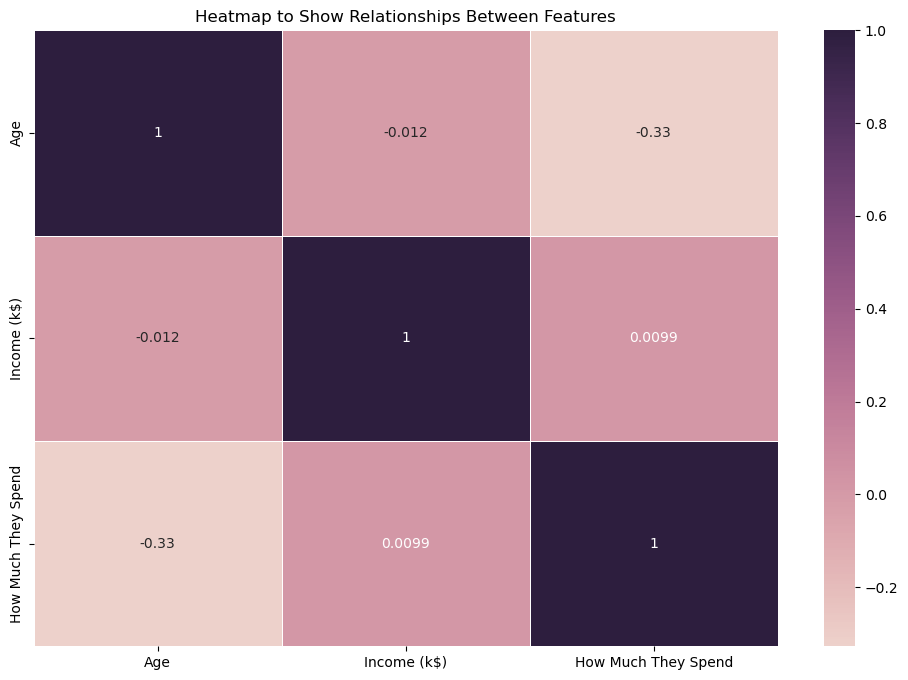

In [ ]:
heatmap_cols = ['Age', 'Income (k$)', 'How Much They Spend']

# .corr() computes how strongly each number-based feature relates to another
# `numeric_only=True` ensures text columns aren't included to avoid errors
corr_matrix = customer_df[heatmap_cols].corr(numeric_only=True)

plt.figure(figsize=(12, 8))

# `annot=True` → prints correlation values inside each cell
# The heatmap helps us quickly see strong (+1 or near) or weak (0 or near) relationships
sns.heatmap(corr_matrix, annot=True, cmap=sns.cubehelix_palette(as_cmap=True), linewidths=0.5)

# Title for heatmap
plt.title('Heatmap to Show Relationships Between Features')

# Display heatmap
plt.show()

- The heatmap is used to visualize the correlation between each feature.

### **Key Insights of the Heatmap:**
- Relationship between Age and Income:
    - Correlation between age and income is near-zero but negative (-0.012), indicating a very weak negative to almost no linear relationship between the two features. (Both are independent information)
    - Suggests that income is distributed relatively evenly across the different age ranges in the dataset. 
- Relationship between Income and Spending:
    - Correlation between income and spending is also near-zero but positive (0.0099), indicating a very small, almost non-existent positive linear relationship. However, due to its small value, the correlation between the two features can be taken as almost no linear relationship.
    - Shows that customers with a higher income may not necessarily spend more.
    - Highlights that customers that have similar incomes have different spending habits, some might spend more than others, but it still does not mean that higher income results in higher spending.
- Relationship between Age and Spending:
    - Correlation between age and spending is a low to moderate negative correlation (-0.33).
        - Suggests that younger customers tend to spend more while older ones spend lesser. (Spending decreases as Age increase)
    - Not a strong correlation but the strongest and most noticeable relationship as compared to the others.

Overall, no relationship between a pair of features exhibits a strong correlation be it positive or negative, indicating low linear relationship (multicollinearity) in the dataset. This highlights that the change in one feature does not affect the change in other features.
        


## **Visual Representation 3:** Pairplot
- Similar to the heatmap, the pairplot compares relationships between features, but instead of displaying correlation values, it visualises these relationships using scatter plots.